<h1 style="font-size:40px;"><center>Exercise I:<br> Training of simple MLP models
</center></h1>

# Introduction
## Short summary
In this exercise you will: 

* train MLPs for simple classification and regression problems.
* learn how hyper-parameters such as learning rate, batch size and number of epochs affect training.

You should write the report of the exercise within this notebook. The details of how to do that can be found below in section "Writing the report".

**Deadline for submitting the report: See Canvas assignment.**

## The data
We will use two synthetic different data sets in this exercise

### syn2
The *syn2* dataset represents a binary classification problem. The input data is 2D which allows for an easy visual inspection of the different classes and the decision boundary implemented by the network. The dataset is generated using random numbers each time you run the cell. This means that each time you generate the data it will be slightly different. You can control this by having a fixed *seed* to the random number generator. The cell "PlotData" will plot the *syn2* dataset.

### regr1
The *regr1* dataset represents a regression problem. It has one input and one target variable. It a cosine function, with the possibility to add some noise and dampening on the output. Again see the cell "PlotData" to look at the dataset.

## The exercises
There are 8 questions in this exercise. These 8 questions can be found in three different cells below (see section "The Different Cells"). The first 6 questions will use the *regr1* dataset and questions 7-8 will use *syn2*.

## The different 'Cells'
This notebook contains several cells with python code, together with the markdown cells (like this one) with only text. Each of the cells with python code has a "header" markdown cell with information about the code. The table below provides a short overview of the code cells. 

| #  |  CellName | CellType | Comment |
| :--- | :-------- | :-------- | :------- |
| 2  | Init | Needed | Sets up the environment|
| 3  | Data | Needed | Defines the functions to generate the artificial datasets |
| 4  | PlotData | Information | Plots the 2D classification datasets |
| 5  | MLP | Needed | Defines the MLP model |
| 6  | Training | Needed | Functions for training and testing the MLP model |
| 7  | Boundary | Needed | Functions for showing classification boundaries and errors | 
| 8  | Ex1 | Exercise | For question 1-4 |
| 9  | Ex2 | Exercise | For question 5-6 |
| 10 | Ex3 | Exercise | For question 7-8 |

To start with the exercise you need to run all cells with the celltype "Needed". The very first time we suggest that you enter each of the needed cells, read the cell instruction and run the cell. It is important that you do this in the correct order, starting from the top and work your way down the cells. Later, when you have started to work with the notebook it may be easier to use the command "Run All" or "Run all above" found in the "Cell" dropdown menu.

## Writing the report
The report should be written within this notebook. We have prepared the last cell in this notebook for you where you should write the report. The report should contain 4 parts:

* Name:
* Introduction: A **few** sentences where you give a short introduction to the content and purpose of the exercise.
* Answers to questions: For each of the questions provide an answer. It can be short answers or longer ones depending on the nature of the questions, but try to be efficient in your writing. (Don't include lots of program output or plots that aren't central to answering the question.)
* Conclusion: Summarize your findings in a few sentences.

It is important that you write the report in this last cell and **not** after each question! 

## Last but not least
Have fun!

---

# CellName: Init (#2)
**CellType: Needed**  
**Cell instruction:**

In the cell below, we will import needed libraries. 

Run the cell by entering into the cell and press "CTRL Enter".

In [867]:
#%pip install torch torchvision torchaudio

import torch
device = 'cpu'
#device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")
# Uncomment this to use CUDA acceleration if available
# device = torch.accelerator.cumrrent_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"PyTorch: Using {device} device")
# The floating point data type can be changed here
dtype_torch = torch.float32

from torch.utils.data import DataLoader, TensorDataset
from torch import nn, Tensor
from collections import OrderedDict
# import torchmetrics

import matplotlib.pyplot as plt
import numpy as np

#torch.manual_seed(42)


Using device: cpu
PyTorch: Using cpu device


# CellName: Data (#3)
**CellType: Needed**  
**Cell instruction:**

This cell defines the two synthetic datasets. The last function is used for standardization of the data. 

Run the cell by entering into the cell and press "CTRL Enter".

In [868]:
def syn2(N):

    "Generate data for classification problem in 2D."
    x = np.empty(shape=(N, 2))
    d = np.empty(shape=(N, 1))
    N1 = N // 2

    # Positive samples
    x[:N1,:] = 0.8 + np.random.normal(size=(N1, 2))
    # Negative samples
    x[N1:,:] = -.8 + np.random.normal(size=(N-N1, 2))

    # Target
    d[:N1] = 1
    d[N1:] = 0

    return x, d

def regr1(N, periods=2, damp=False, v=0):
    #np.random.seed(42)

    "Generate data for 1D regression problem with damped cosine and noise"
    dx = 2*periods*np.pi / (N-1)
    x = np.arange(N) * dx
    if damp:
        d = np.cos(x)*np.exp(-x*0.05)
    else:
        d = np.cos(x)
    noise = lambda n : np.random.normal(size=n)
    std_signal = np.std(d)
    d = d + v * std_signal * noise(N)

    return x[:, None], d[:, None]

def standard(x):
    "Mean and stddev across samples"
    return np.mean(x, axis=0), np.std(x, axis=0)

# CellName: PlotData (#4)
**CellType: Information**  
**Cell instruction:**

Here, we generate 100 cases for *syn2* and *regr1* datasets and plot them. 

Run the cell by entering into the cell and press "CTRL Enter". 

**Note!** This cell is not needed for the actual exercises, it is just to visualize the two datasets.

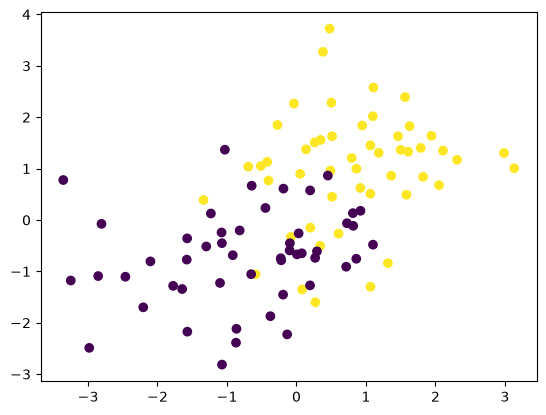

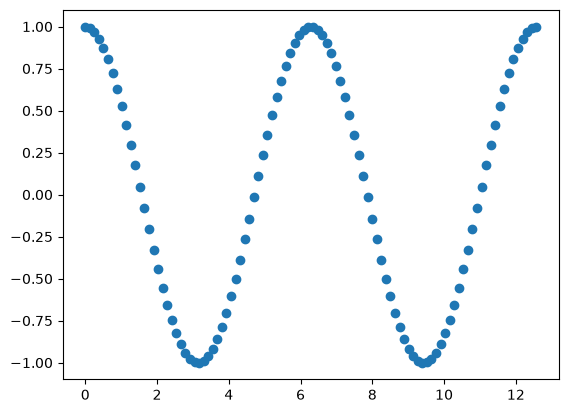

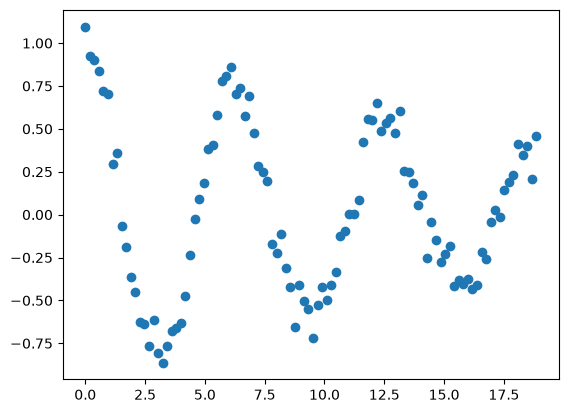

In [869]:
# seed = 0 means random, seed > 0 means fixed
seed = 0
np.random.seed(seed) if seed else None
x, d = syn2(100)
plt.figure()
plt.scatter(x[:,0], x[:,1], c=d)

# Regression, one period, no noise
x, d = regr1(100, 2, False, 0)
plt.figure()
plt.scatter(x, d)

# Regression, 1.5 period, exponential damping, some noise
x, d = regr1(100, 3, True, 0.2)
plt.figure()
plt.scatter(x, d)

# CellName: MLP (#5)
**CellType: Needed**  
**Cell instruction:**

This cell defines the MLP model. Several MLP hyperparameters are needed to define a model.
Here is a list of them:  
(**Note:** They can all be specified when you call
this function in later cells. The ones specified in this cell are the default values.)

* inputs: the input dimension (integer)

* output: the input dimension (integer)

* nodes: size of the network, eg `[5]` for a one hidden layer with 5 nodes and `[5, 3]` for a two layer network with 5 and 3 hidden nodes each.

* activation: the activation function. Most common are
    * `nn.ReLU`
    * `nn.Tanh`<p>
        
* output_activation: the activation function for the output nodes. Most common are
    * `None` (linear activation)
    * `nn.Sigmoid`
    * `nn.Softmax`<p>
      
Run the cell by entering into the cell and press "CTRL Enter".

In [870]:
class Network(nn.Module):
    "A simple MLP with one or more fully connected layers"

    def __init__(self, *, inputs=1, outputs=1, nodes=[4], activation=nn.Tanh, out_activation=None):
        """
        Args:
            inputs (int, optional): The number of input nodes.
            outputs (int, optional): The number of output nodes.
            nodes (list, optional): A list of layer sizes.
            activation: Activation function (or None for linear). Defaults to nn.Tanh
            out_activation (optional): Activation function for output layer.
        """
        super().__init__()

        seqstack = OrderedDict()
        prevn = inputs
        for i, n in enumerate(nodes):
            seqstack[f"layer{i+1}"] = nn.Linear(prevn, n, dtype=dtype_torch)
            prevn = n
            if activation is not None:
                seqstack[f"act{i+1}"] = activation()
        seqstack["layerN"] = nn.Linear(prevn, outputs, dtype=dtype_torch)
        if out_activation is not None:
            seqstack["actN"] = out_activation()
        self.mlp_stack = nn.Sequential(seqstack)

    def forward(self, x : Tensor):
        "Apply the network stack on some input"
        return self.mlp_stack(x)

    def predict(self, input_data):
        """
        Apply the network on a set of input data.

        Args:
            input_data (np.ndarray): Input data

        Returns:
            pred (np.ndarray): Predicted output.
        """
        self.eval()
        inp = torch.tensor(input_data, dtype=dtype_torch, device=device)
        with torch.no_grad():
            pred = self(inp)
        return pred.cpu().numpy()

    def __str__(self):
        s = super().__str__()
        ps = ["Named parameters:"] + [
            f"{name}: {param.numel()}" for name, param in
             self.mlp_stack.named_parameters() if param.requires_grad]
        totp = sum(p.numel() for p in self.mlp_stack.parameters() if p.requires_grad)
        return s + f"\nTrainable parameters: {totp}\n" + "\n  ".join(ps) + "\n"

# CellName: Training (#6)
**CellType: Needed**  
**Cell Instruction:**

This cell defines functions for training the model for a single epoch (`train_epoch`),
evaluating the performance in the validation data (`test`) and training and validating over
many epochs (`train_loop`). Finally, it defines a function (`plot_training`) for plotting
the training progress.

The `train_loop` function takes a previously defined `Network` model, two PyTorch `DataLoader`s
that provide the data for training and test, and several hyperparameters:

* loss_fn: The error function used during training. There are three common ones
    * `nn.MSELoss` (mean squared error)
    * `nn.BCELoss` (binary cross entropy)
    * `nn.CrossEntropyLoss` (categorical cross entropy)<p>

* optimizer: The error minimization method, which is constructed with information about the model and a learning rate. Common choices are
    * `torch.optim.SGD`
    * `torch.optim.Adam`<p>

* metrics: Additional metrics to compute and print besides the loss. We have made our own metrics based on how the [torcheval.metrics package](https://docs.pytorch.org/torcheval/main/torcheval.metrics.html) is used. Our metrics classes are defined below. Pass the metric(s) as a dict with `{name: metric}`. Examples:
    * `{'accuracy': BinaryAccuracyMetric()}`
    * `{'MSE': MSEMetric()}`<p>

Run the cell by entering into the cell and press "CTRL Enter".

In [879]:
def train_epoch(*, model : Network, dataloader : DataLoader,
                loss_fn, optimizer : torch.optim.Optimizer, metrics=[]):
    """
    Train a model for a single epoch.

    Args:
        model (Network): The network.
        dataloader (DataLoader): Batch DataLoader with training data.
        loss_fn (Loss): Loss function, e.g. nn.MSELoss.
        optimizer (Optimizer): The optimizer used to update the network.
        metrics (iterable): Additional metrics to update.

    Returns:
        train_loss (float): Training error over all batches.
    """
    model.train()
    train_loss = 0
    for X, y in dataloader:
        X, y = X.to(device), y.to(device)   # Move data to GPU if necessary
        optimizer.zero_grad()   # Reset the gradients

        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)
        train_loss += loss.item() * len(X)
        for m in metrics:
            m.update(pred.detach(), y)

        # Backpropagation
        loss.backward()
        optimizer.step()
    return train_loss / len(dataloader.dataset)

def print_final_msg(print_final, val_losses, metrics_res):
    if print_final:
        print("\n** Validation metrics after training **\n"
            f"Loss {val_losses[-1]:<7g}")
        for n, v in metrics_res.items():
            if torch.isreal(v[-1]):
                print(f"{n} {v[-1]:<7g}")
            else:
                print(f"{n}:")
                print(v[-1])
        print()


def test(*, model : Network, dataloader : DataLoader, loss_fn, metrics=[]):
    """
    Test a model on a set of data.

    Args:
        model (Network): The network.
        dataloader (DataLoader): DataLoader with data to test.
        loss_fn (Loss): Loss function, e.g. nn.MSELoss.
        metrics (iterable): Additional metrics to update.

    Returns:
        loss (float): Mean error over all batches.
    """
    model.eval()
    loss = 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss += loss_fn(pred, y).item() * len(X)
            for m in metrics:
                m.update(pred, y)
    return loss / len(dataloader.dataset)


def train_loop(*, model : Network, train_dataloader : DataLoader,
               val_dataloader : DataLoader = None, loss_fn,
               optimizer : torch.optim.Optimizer, epochs : int,
               print_every:int = 100, metrics=None, print_final=True):
    """
    Train and optionally test a model.

    Args:
        model (Network): The network.
        train_dataloader (DataLoader): Training data.
        val_dataloader (DataLoader, optional): Validation data.
        loss_fn (Loss): Loss function, e.g. nn.MSELoss.
        optimizer (Optimizer): An optimizer from torch.optim.
        epochs (int): Number of epochs to train for.
        print_every (int, optional): Print loss every so many epochs. Defaults to 100.
        metrics (dict(name: metric), optional): Record/print these additional metrics.
        print_final(bool, optional): Print final metrics. Defaults to True.

    Returns:
        train_losses (list(float)): Training loss during each epoch.
        val_losses (list(float)): Validation loss after each epoch.
        metrics_res (dict(name: list(float))): Values of metrics after each epoch.
    """
    train_losses = []
    val_losses = []
    val_loss = np.nan
    min_epoch = 0
    patience  = 10000000 # epoch_validation_threshold
    # Move metrics to CPU/GPU and prepare for their output
    metrics = {name: m.to(device) for name, m in (metrics or {}).items()}
    metrics_res = {name+"-t": [] for name in metrics.keys()}
    metrics_res.update({name+"-v": [] for name in metrics.keys()})

    for t in range(epochs):
        for m in metrics.values():
            m.reset()
        train_loss = train_epoch(model=model, dataloader=train_dataloader,
                           loss_fn=loss_fn, optimizer=optimizer,
                           metrics=metrics.values())
        train_losses.append(train_loss)
        for name, m in metrics.items():
            metrics_res[name+"-t"].append(m.compute().cpu())

        if val_dataloader is not None:
            for m in metrics.values():
                m.reset()
            val_loss = test(dataloader=val_dataloader, model=model,
                            loss_fn=loss_fn, metrics=metrics.values())
            val_losses.append(val_loss)
            for name, m in metrics.items():
                metrics_res[name+"-v"].append(m.compute().cpu())

        if (print_every > 0 and t % print_every == 0) or (
                print_every >= 0 and t + 1 == epochs):
            extras = [f" {n} {v[-1]:<7f}" if torch.isreal(v[-1])
                      else f" {n} {v[-1]}"
                      for n, v in metrics_res.items()]
            print(f"Epoch {t+1:<7d} train {train_loss:<7f} "
                  f" validation {val_loss:<7f}", "".join(extras))
        '''   
        for name, m in metrics.items():
            if(metrics_res[name+"-t"][t] < 0.01):
                print("MSE-t < 0.01 , epochs", t)
                #print_final_msg(print_final, val_losses, metrics_res)
                return train_losses, val_losses, metrics_res, t 
        '''  
        '''
        for name, m in metrics.items():
            if(metrics_res[name+"-t"][t] > 0.95):
                print("train_acc > 0.95 , epochs", t)
                print_final_msg(print_final, val_losses, metrics_res)
                return train_losses, val_losses, metrics_res, t 
        '''

#        if(val_losses[t] < val_losses[min_epoch]):
#            min_epoch = t

        if(val_losses[t] < 0.0003):
            print("val_losses > 0.0003 , epochs", t)
            print_final_msg(print_final, val_losses, metrics_res)
            return train_losses, val_losses, metrics_res, t 
        '''
        if(min_epoch + patience < t):
            print("Early quit at epoch:", min_epoch)
            print_final_msg(print_final, val_losses, metrics_res)
            for name, m in metrics.items():
                metrics_res[name+"-t"] = metrics_res[name+"-t"][:-patience]
                metrics_res[name+"-v"] = metrics_res[name+"-v"][:-patience]

            return train_losses[:-patience], val_losses[:-patience], metrics_res, t-patience
        '''
    print_final_msg(print_final, val_losses, metrics_res)
    return train_losses, val_losses, metrics_res, t      

    

def plot_training(train_loss, val_loss, metrics_res={}):
    "Plot the training history"
    plt.figure()
    #plt.ylim(0,1)
    plt.ylabel('Loss / Metric')
    plt.xlabel('Epoch')
    plt.plot(train_loss, label="Training loss")
    plt.plot(val_loss, label="Validation loss")
    for name, res in metrics_res.items():
        if torch.isreal(res[0]):
            plt.plot(res, label=name)
    plt.legend(loc='best')
    plt.grid()
    plt.show()

class SimpleMetric():
    """ Base class for any metric that keeps a numerator and denominator,
    designed as a simple drop-in replacement for torchmetrics.
    """
    def __init__(self, v=None):
        if v is not None:
            self.v = v
        else:
            self.v = torch.zeros(2)

    def reset(self):
        self.v = torch.zeros_like(self.v)

    def to(self, device):
        v = self.v.to(device)
        return self if v is self.v else type(self)(v)

    def compute(self):
        return self.v[0] / self.v[1]

class MSEMetric(SimpleMetric):
    """ Mean square error metric.
    """
    def update(self, pred, y):
        self.v[0] += ((pred - y)**2).sum()
        self.v[1] += y.numel()

class BinaryAccuracyMetric(SimpleMetric):
    """ Binary accuracy metric. Predictions will be thresholded at 0.5.
    """
    def update(self, pred, y):
        if pred.is_floating_point():
            pred = pred >= .5
        self.v[0] += (pred == y).sum()
        self.v[1] += y.numel()

def standard_err(mean, samples):
    err = 0
    div = 0
    N = len(samples)
    for i in range(N):
        div += (samples[i] - mean)**2
    err = np.sqrt(div/(N*(N-1)))
    return err

# CellName: Boundary (#7)
**CellType: Needed**  
**Cell Instruction:**

This cell defines a function for presenting the output of binary MLP classifiers, plotting the decision boundary for a problem with 2D input. In brief, this function defines a grid that covers the input data. Each grid point is then used as an input to the trained MLP and to compute an output. If the output is close to 0.5 it is marked as the boundary.

Run the cell by entering into the cell and press "CTRL Enter".

In [872]:
def decision_boundary(X : np.ndarray, Y1 : np.ndarray, model):
    """
        Plot classfication and decision boundary for binary classification problem

        Args:
            X (np.ndarray): input
            Y1 (np.ndarray): target
            model (Network): the model

        Returns:
            None.
    """
    x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
    y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
    # grid stepsize
    h = 0.025

    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    Z[Z > .5] = 1
    Z[Z <= .5] = 0

    Y_pr = model.predict(X).flatten()
    Y = Y1.flatten()

    Y_pr[Y_pr > .5] = 1
    Y_pr[Y_pr <= .5] = 0
    Y[(Y != Y_pr) & (Y == 0)] = 2
    Y[(Y != Y_pr) & (Y == 1)] = 3

    plt.figure()
    #plt.contourf(xx, yy, Z, cmap=plt.cm.PRGn, alpha = .9)
    plt.contour(xx, yy, Z, cmap=plt.cm.Paired)

    plt.scatter(X[Y == 1, 0], X[Y == 1, 1], marker='+', c='k')
    plt.scatter(X[Y == 0, 0], X[Y == 0, 1], marker='o', c='k')

    plt.scatter(X[Y == 3, 0], X[Y == 3, 1], marker = '+', c='r')
    plt.scatter(X[Y == 2, 0], X[Y == 2, 1], marker = 'o', c='r')
    plt.grid()
    plt.ylabel('x2')
    plt.xlabel('x1')
    plt.show()

---
End of "Needed" and "Information" cells. Below are the cells for the actual exercise.

---

# CellName: Ex1 (#8)
**CellType: Exercise**  
**Cell instruction:**

Questions 1-4 look at three essential parameters that controls the training process of an MLP: the *learning rate*, *batch size* and *number of epochs* (or epochs for short). By training process we mean here the minimization of the given loss function. The task is to train an MLP with four hidden nodes that can fit the *regr1* dataset. In this version of the dataset, there is no noise. Therefore, we need not specify any seed.

The dataset and network have been selected so that it is possible, but not trivial, to get a good training result.
A successful training means here when the networks has reached a loss < 0.01, and visually have fitted the data accurately. In this exercise we do not care about possible overfitting, only about the minimization of the loss function, we therefore do not have a validation dataset.

## Question 1, variations in pre-defined MLP
For the first question you can simply run the cell below. It will load 50 samples from the *regr1* dataset (no noise added). The network has 4 hidden nodes in a single hidden layer, *tanh* activation function, linear output activation function, *stochastic gradient descent* as minimization method, MSE loss function, and a learning rate of 0.05.
It will train for 4000 epochs using a batchsize of 60, meaning that we efficiently are using ordinary gradient descent learning. Run this cell five times. **(a) Do you see the same loss vs epoch behavior each time your run?** If not, **why?** **(b) Do you observe that training fails, i.e. do not reach low loss, during any of these five runs?** 

## Question 2, vary learning rate
You will now study what happens when you train with different learning rates. Test at least 5 different learning rates in the range from 0.001 to 0.5. For each learning rate train the network three times and record the average MSE value over these three runs. **Present your average MSE results and discuss your findings**.

**Note:** You should keep the same settings as for Q1, only vary the learning rate. The learning rate is best investigated with (roughly) proportional changes rather than constant steps: For example, trying 0.5, 0.2, 0.1, 0.05, 0.02 etc. typically gives more interesting results than 0.5, 0.4, 0.3, 0.2, 0.1.

## Question 3, vary (mini)batch size
We now (hopefully) have discovered that the learning rate influences the efficiency of the loss minimization. We will now look at what happens when we use *stochastic gradient descent*, meaning that we will have a "batch size" that is smaller the the size of the training data. (We now adapt to the language of ANN packages such as PyTorch and use the word "batch" where most literature would use "mini-batch".) Use a fixed learning rate of 0.05, but test different batch sizes in the range 1 to 60. Train three different networks for each batch size, but this time record if the training was successful (i.e. MSE < 0.01) and approximately after how many epochs the good solution was found. **Present and discuss your findings**.

**Note:** The batch size should (ideally) divide the total data size. With a data size of 60, we have a large range of "good" batch sizes: 1, 2, 3, 4, 5, 6, 10, 12, 15, 20, 30, 60. Sizes that fit poorly, like 50, create a small last batch, which could give you the disadvantages of both small and large batch sizes at the same time.

## Question 4, select good hyper-parameters
Find a combination of learning rate and batch size that gives a good solution within 1000 epochs. We always have to remember that two runs with identical hyper parameters (e.g. learning rate, batch size etc) will result in different final results. Your set of parameters should *most* of the times result in a good solution within 1000 epochs. **Present your best combination of learning rate and batch size, and its result**.

hi 2
Network(
  (mlp_stack): Sequential(
    (layer1): Linear(in_features=1, out_features=4, bias=True)
    (act1): Tanh()
    (layerN): Linear(in_features=4, out_features=1, bias=True)
  )
)
Trainable parameters: 13
Named parameters:
  layer1.weight: 4
  layer1.bias: 4
  layerN.weight: 4
  layerN.bias: 1

Epoch 1       train 0.589152  validation 0.578632  MSE-t 0.589152 MSE-v 0.578632
Epoch 1000    train 0.382183  validation 0.378974  MSE-t 0.382183 MSE-v 0.378974

** Validation metrics after training **
Loss 0.378974
MSE-t 0.382183
MSE-v 0.378974

hi 2
Network(
  (mlp_stack): Sequential(
    (layer1): Linear(in_features=1, out_features=4, bias=True)
    (act1): Tanh()
    (layerN): Linear(in_features=4, out_features=1, bias=True)
  )
)
Trainable parameters: 13
Named parameters:
  layer1.weight: 4
  layer1.bias: 4
  layerN.weight: 4
  layerN.bias: 1

Epoch 1       train 0.562415  validation 0.518141  MSE-t 0.562415 MSE-v 0.518141
Epoch 1000    train 0.000962  validation 0.000923  MSE-

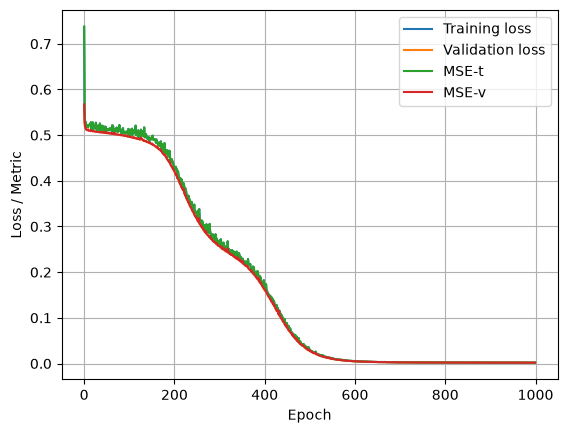

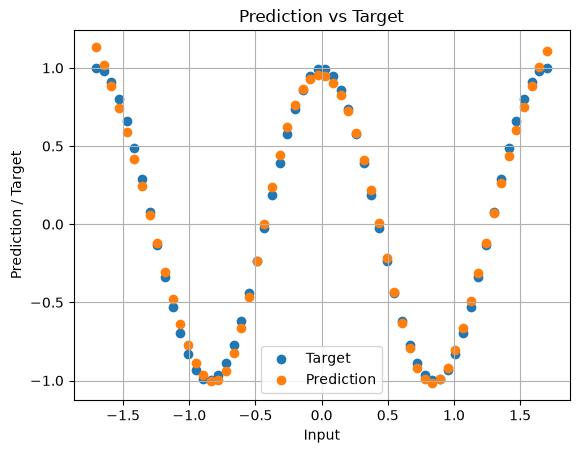

CPU times: user 2min 51s, sys: 853 ms, total: 2min 52s
Wall time: 2min 53s


In [890]:
%%time

batches = [1, 2, 3, 4, 5, 6, 10]#, 12, 15, 20, 30, 60] #[60]#(3, 4, 5, 6, 10, 12, 15, 20, 30)
learning_rate_grid = [0.001, 0.01, 0.05]#, 0.1, 0.25]

# Generate training data

# Optimization parameters
n1 = 3
n2 = len(batches)
n3 = len(learning_rate_grid)

batch_loss = np.zeros((n1,n2,n3))
epoch_arr = np.zeros((n1,n2,n3))
for i in range(n1):
    x_trn, d_trn = regr1(60, 2, 0, 0.0)

        # Standardization of inputs
    mu, std = standard(x_trn)
    x_trn = (x_trn - mu) / std

    for j in range(n2):
        for k in range(n3):
            # Define the network, cost function and training settings
            model_ex1 = Network(
                inputs=1,            # number of input nodes
                outputs=1,           # number of output nodes
                nodes=[4],           # number of nodes in hidden layer
                activation=nn.Tanh,  # activation function in hidden layer
                out_activation=None  # activation function in output layer (if not linear)
                ).to(device)         # move data to GPU or keep with CPU

            print("hi 2")
            opt_method = torch.optim.SGD  # minimization method
            learning_rate = learning_rate_grid[k]       # learning rate,  0.001 to 0.5: 0.001, 0.01, 0.1, 0.25,0.5
            loss_fn = nn.MSELoss()        # loss function, MSE
            number_epochs = 1000
            minibatch_size = batches[j]

            # Additional metrics to print
            metrics = {'MSE': MSEMetric()}

            # Set up the optimizer
            optimizer = opt_method(model_ex1.parameters(), lr=learning_rate)

            # Print a summary of the model
            print(model_ex1)

            # Turn the training data into a dataset with Tensors on the GPU or CPU
            dset_trn = TensorDataset(torch.tensor(x_trn, device=device, dtype=dtype_torch),
                                        torch.tensor(d_trn, device=device, dtype=dtype_torch))

            # Create a batch loader for the training data, with reshuffling each epoch for SGD.
            dl_trn = DataLoader(dset_trn, batch_size=minibatch_size, shuffle=True)

            # Train the network and print the progress


            train_loss, val_loss, metrics_res, epochs_train = train_loop(
                model=model_ex1,
                train_dataloader=dl_trn,
                val_dataloader=dl_trn, # Test with the training data
                loss_fn=loss_fn,
                metrics=metrics,
                optimizer=optimizer,
                print_every=1000000,
                epochs=number_epochs)
            epoch_arr[i][j][k] = epochs_train
            batch_loss[i][j][k] = val_loss[-1]
            
            
print("asdsds")
for j in range(n2):
    for k in range(n3):
        summation = 0
        for i in range(n1):
            summation += batch_loss[i][j][k]
        err = standard_div(summation / n1, batch_loss[:,j,k])
        print("batch",batches[j]," , learning rate",learning_rate_grid[k]," , batch_loss:",summation / n1 ,"+-", err)
'''  
''' 
# Plot the training history
plot_training(train_loss, val_loss, metrics_res)

# Predict output on the training data
d_pred = model_ex1.predict(x_trn)

# Plot the result
plt.figure()
plt.grid()
plt.ylabel('Prediction / Target')
plt.xlabel('Input')
plt.scatter(x_trn, d_trn, label='Target')
plt.scatter(x_trn, d_pred, label='Prediction')
plt.title('Prediction vs Target')
plt.legend(loc='best')
plt.show()


In [742]:
print("PyTorch version:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())
print("MPS built:", torch.backends.mps.is_built())

PyTorch version: 2.15.0
MPS available: True
MPS built: True


# CellName: Ex2 (#9)
**CellType: Exercise**  
**Cell instruction:**  

The amount of weights in the network can also influence how long time we need to train, and of course if the problem itself is complex or not. The following two questions will highlight this.

## Question 5, vary epochs
The example below will load a slightly more complex *regr1* problem (an additional quarter of a period). We will use 10 hidden nodes for this problem. Use your optimal set of learning rate and batch size as found in Q4 and train the network below. **Compare the number of epochs needed to reach a good solution with that of Q4**. Note, you may need to vary the number of epochs a lot! If you cannot find a good solution in a reasonable number of epochs, you can "revert" the problem: optimize learning rate and batch size for Q5, and the see how those hyper-parameters perform on Q4.

## Question 6, vary network size and other hyper-parameters
Use the following line to load the *regr1* data set:

`x_trn, d_trn = regr1(75, 5, 1, 0.0)`

This will create an even more challenging regression task that may need an even larger network. Your task is to find a set of hyper-parameters (learning rate, batch size, epochs, 'size of the network') that result in a good solution. You can use more than one hidden layer for this task (if you want). To create many hidden layers, add numbers to the `nodes` list, for example: `nodes = [10, 5, 5]`. **Present your set of good hyper-parameters and the result**. 

**Note:** If you cannot solve this task in *reasonable* time, present your best attempt!


Network(
  (mlp_stack): Sequential(
    (layer1): Linear(in_features=1, out_features=10, bias=True)
    (act1): Tanh()
    (layerN): Linear(in_features=10, out_features=1, bias=True)
  )
)
Trainable parameters: 31
Named parameters:
  layer1.weight: 10
  layer1.bias: 10
  layerN.weight: 10
  layerN.bias: 1

Epoch 1       train 0.614284  validation 0.508994  MSE-t 0.614284 MSE-v 0.508994
Epoch 101     train 0.520350  validation 0.512911  MSE-t 0.520350 MSE-v 0.512911
Epoch 201     train 0.510099  validation 0.498427  MSE-t 0.510099 MSE-v 0.498427
Epoch 301     train 0.337239  validation 0.332359  MSE-t 0.337239 MSE-v 0.332359
Epoch 401     train 0.355366  validation 0.306145  MSE-t 0.355366 MSE-v 0.306145
Epoch 501     train 0.343322  validation 0.295506  MSE-t 0.343322 MSE-v 0.295506
Epoch 601     train 0.315825  validation 0.292318  MSE-t 0.315825 MSE-v 0.292318
Epoch 701     train 0.315130  validation 0.306591  MSE-t 0.315130 MSE-v 0.306591
Epoch 801     train 0.343324  validation 0.2

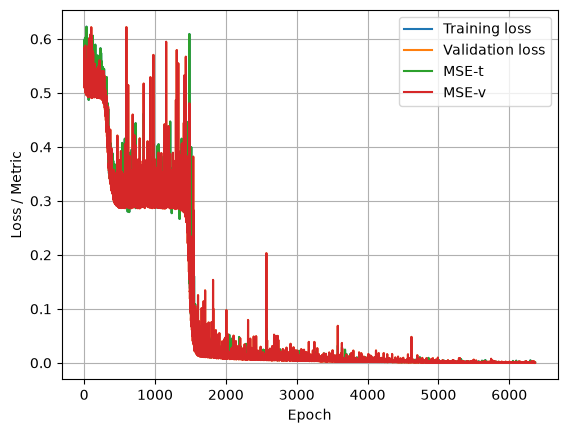

CPU times: user 1min, sys: 576 ms, total: 1min 1s
Wall time: 1min 1s


AttributeError: 'list' object has no attribute 'shape'

In [771]:
'''
%%time

# seed = 0 means random, seed > 0 means fixed
seed = 0
np.random.seed(seed) if seed else None

# Generate training data
# For Q5:
#x_trn, d_trn = regr1(60, 2.5, 0, 0.0)

# For Q6:
x_trn, d_trn = regr1(75, 5, 1, 0.0)

n1 = 5

epoch_arr = np.zeros(n1)

# Standardization of inputs
for i in range(n1):
    mu, std = standard(x_trn)
    x_trn = (x_trn - mu) / std

    #| 6  | 0.1 | $ 0.0011 \pm 0.0003$ | 


    # Define the network, cost function and training settings
    model_ex2 = Network(
        inputs=1,            # number of input nodes
        outputs=1,           # number of output nodes
        nodes=[10],           # number of nodes in hidden layer
        activation=nn.Tanh,  # activation function in hidden layer
        out_activation=None  # activation function in output layer (if not linear)
        ).to(device)         # move data to GPU or keep with CPU

    # Optimization parameters
    opt_method = torch.optim.SGD  # minimization method
    learning_rate = 0.1          # learning rate
    loss_fn = nn.MSELoss()        # loss function, MSE
    number_epochs = 100000
    minibatch_size = 6

    # Additional metrics to print
    metrics = {'MSE': MSEMetric()}

    # Print a summary of the model
    print(model_ex2)

    # Set up the optimizer
    optimizer = opt_method(model_ex2.parameters(), lr=learning_rate)

    # Turn the training data into a dataset with Tensors on the GPU or CPU
    dset_trn = TensorDataset(torch.tensor(x_trn, device=device, dtype=dtype_torch),
                            torch.tensor(d_trn, device=device, dtype=dtype_torch))

    # Create a batch loader for the training data, with reshuffling each epoch for SGD.
    dl_trn = DataLoader(dset_trn, batch_size=minibatch_size, shuffle=True)

    # Train the network and print the progress
    train_loss, val_loss, metrics_res, epochs_train = train_loop(
        model=model_ex2,
        train_dataloader=dl_trn,
        val_dataloader=dl_trn, # Test with the training data
        loss_fn=loss_fn,
        metrics=metrics,
        optimizer=optimizer,
        print_every=100,
        epochs=number_epochs)

    epoch_arr[i] = epochs_train
    #batch_loss[i] = val_loss[-1]
            
            
print("asdsds")
summation = 0
for i in range(n1):
    summation += epoch_arr[i]
err = standard_div(summation / n1, epoch_arr)
print("loss:",summation / n1 ,"+-", err)

# Plot the training history
plot_training(train_loss, val_loss, metrics_res)

indices = np.unravel_index(np.argmin(val_loss[-1]), val_loss.shape)
# Predict output on the training data
d_pred = model_ex2.predict(x_trn)

# Plot the result
plt.figure()
plt.ylabel('Prediction / Target')
plt.xlabel('Input')
plt.scatter(x_trn, d_trn, label='Target')
plt.scatter(x_trn, d_pred, label='Prediction')
plt.title('Prediction vs Target')
plt.legend(loc='best')
plt.show()
'''

loop no. 0  , batch 4  , learning rate 0.05  , nodes [4]
Epoch 1       train 0.585184  validation 0.545543  MSE-t 0.585184 MSE-v 0.545543
Epoch 1001    train 0.000337  validation 0.000363  MSE-t 0.000337 MSE-v 0.000363
val_losses > 0.0003 , epochs 1172

** Validation metrics after training **
Loss 0.000297804
MSE-t 0.000338756
MSE-v 0.000297804

best_batches[i] 0
best_learning_rate[i] 0
best_node[i] 0
loop no. 1  , batch 4  , learning rate 0.05  , nodes [4]
Epoch 1       train 0.723629  validation 0.530664  MSE-t 0.723629 MSE-v 0.530664
Epoch 1001    train 0.000949  validation 0.000803  MSE-t 0.000949 MSE-v 0.000803
Epoch 2001    train 0.000553  validation 0.000525  MSE-t 0.000553 MSE-v 0.000525
Epoch 3001    train 0.000425  validation 0.000426  MSE-t 0.000425 MSE-v 0.000426
val_losses > 0.0003 , epochs 3921

** Validation metrics after training **
Loss 0.000298565
MSE-t 0.000373819
MSE-v 0.000298565

best_batches[i] 0
best_learning_rate[i] 0
best_node[i] 0
loop no. 2  , batch 4  , lea

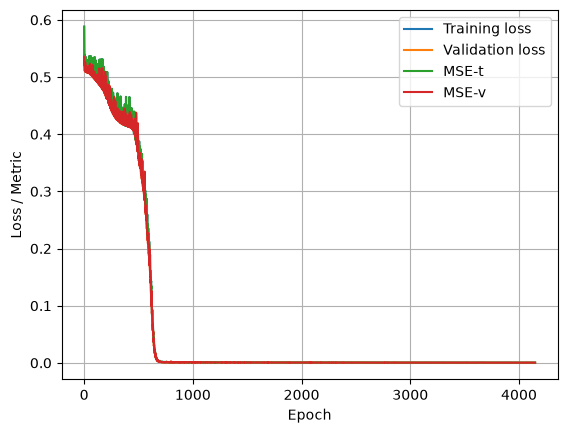

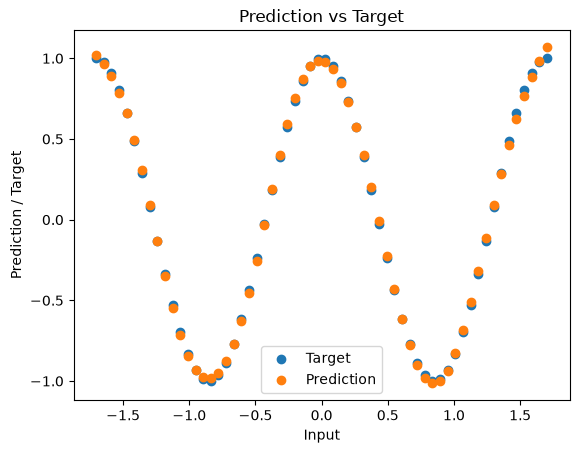

CPU times: user 17.8 s, sys: 124 ms, total: 18 s
Wall time: 18 s


In [889]:
%%time
batches = [4]#, 6, 10]#, 12, 15, 20, 30)
learning_rate_grid = [0.05]#, 0.03, 0.1]#, 0.25]
node_grid = [[4]]
'''[[4],
            [5,5],
            [10,5,5],
            [5,10,10,5]]
'''

n1 = 3
n2 = len(batches)
n3 = len(learning_rate_grid)
n4 = len(node_grid)

epoch_train = np.zeros((n1,n2,n3,n4))
best_batches = np.zeros(n1, dtype=int)
best_learning_rate = np.zeros(n1, dtype=int)
best_node = np.zeros(n1, dtype=int)
epochs = 100000
min_epochs = np.full(n1, epochs-1)

seed = 0
np.random.seed(seed) if seed else None
for i in range(n1):
    x_trn, d_trn = regr1(60, 2, 0, 0.0)

    # For Q6:
    #x_trn, d_trn = regr1(75, 5, 1, 0.0)

    # Standardization of inputs
    mu, std = standard(x_trn)
    x_trn = (x_trn - mu) / std


    for j in range(n2):
        for k in range(n3):
            for l in range(n4):
                print("loop no.", i, " , batch",batches[j]," , learning rate",learning_rate_grid[k]," , nodes",node_grid[l])
                # seed = 0 means random, seed > 0 means fixed


                # Generate training data
                # For Q5:


                # Define the network, cost function and training settings
                model_ex2 = Network(
                    inputs=1,            # number of input nodes
                    outputs=1,           # number of output nodes
                    nodes=node_grid[l],           # number of nodes in hidden layer
                    activation=nn.Tanh,  # activation function in hidden layer
                    out_activation=None  # activation function in output layer (if not linear)
                    ).to(device)         # move data to GPU or keep with CPU

                # Optimization parameters
                #opt_method = torch.optim.SGD  # minimization method
                opt_method = torch.optim.SGD  # minimization method
                learning_rate = learning_rate_grid[k]         # learning rate
                loss_fn = nn.MSELoss()        # loss function, MSE
                number_epochs = min_epochs[i]+1
                minibatch_size = batches[j]

                # Additional metrics to print
                metrics = {'MSE': MSEMetric()}

                # Print a summary of the model
                #print(model_ex2)

                # Set up the optimizer
                optimizer = opt_method(model_ex2.parameters(), lr=learning_rate)

                # Turn the training data into a dataset with Tensors on the GPU or CPU
                dset_trn = TensorDataset(torch.tensor(x_trn, device=device, dtype=dtype_torch),
                                        torch.tensor(d_trn, device=device, dtype=dtype_torch))

                #dset_val = TensorDataset(torch.tensor(x_val, device=device, dtype=dtype_torch),
                #                        torch.tensor(d_val, device=device, dtype=dtype_torch))

                # Create a batch loader for the training data, with reshuffling each epoch for SGD.
                dl_trn = DataLoader(dset_trn, batch_size=minibatch_size, shuffle=True)
                #dl_val = DataLoader(dset_val, batch_size=minibatch_size, shuffle=True)

                # Train the network and print the progress
                train_loss, val_loss, metrics_res, epoch_t = train_loop(
                    model=model_ex2,
                    train_dataloader=dl_trn,
                    val_dataloader=dl_trn, # Test with the training data???
                    loss_fn=loss_fn,
                    metrics=metrics,
                    optimizer=optimizer,
                    print_every=1000,
                    epochs=number_epochs)
                epoch_train[i][j][k][l] = epoch_t
                
                if(epoch_t < min_epochs[i]):
                    #min_epochs[i] = int(epoch_t)
                    best_batches[i] = int(np.round(j))
                    best_learning_rate[i] = int(np.round(k))
                    best_node[i] = int(np.round(l))
                    print("best_batches[i]",best_batches[i])
                    print("best_learning_rate[i]",best_learning_rate[i])
                    print("best_node[i]",best_node[i])
                
                

for i in range(n1):
    print("dataset",i,"batch",batches[best_batches[i]]," , learning rate",learning_rate_grid[best_learning_rate[i]]," , Nodes",node_grid[best_node[i]], "epoch:", min_epochs[i])

summation = np.zeros((n2, n3, n4))
for j in range(n2):
    for k in range(n3):
        for l in range(n4):
            for i in range(n1):
                summation[j][k][l] += epoch_train[i][j][k][l]
            err = standard_div(summation[j][k][l] / n1, epoch_train[:,j,k,l])
            print("batch",batches[j]," , learning rate",learning_rate_grid[k]," , Nodes",node_grid[l], " , MSE:",summation[j][k][l] / n1 ,"+-", err)

# Plot the training history

indices = np.unravel_index(np.argmin(summation), summation.shape)
print("indices:", indices)
'''
'''
plot_training(train_loss, val_loss, metrics_res)

# Predict output on the training data
d_pred = model_ex2.predict(x_trn)

# Plot the result
plt.figure()
plt.ylabel('Prediction / Target')
plt.xlabel('Input')
plt.scatter(x_trn, d_trn, label='Target')
plt.scatter(x_trn, d_pred, label='Prediction')
plt.title('Prediction vs Target')
plt.legend(loc='best')
plt.show()


# CellName: Ex3 (#10)
**CellType: Exercise**  
**Cell instruction:**  

We will now look at the classification problem defined by the *syn2* dataset.
The cell below defines a single hidden node MLP. With this network you can only implement a linear decision boundary. Run the cell below to look at the resulting boundary that the MLP learns. The training accuracy is around 87-93%, because the data is generated randomly each time you run the code. 

## Question 7, optimize hyper-parameters for classification
Your task is now to reach a larger accuracy by fitting a model with more hidden nodes (and possibly more hidden layers). 
Your aim is to reach a training accuracy > 95%. To do that you need to tune the learning rate, batch size, epochs and the size of your MLP. **Present your set of hyper parameters that reach > 95% accuracy**

**Note**: To always generate exactly the same dataset each time you run the code you can set the *seed* to a value > 0. 

## Question 8, change learning algorithm
We have so far only used stochastic gradient descent (SGD), but we know that there are modifications of SGD that are very popular, e.g. Adam.
**Try the Adam optimizer for Q7, and compare (qualitatively) the results and the number of epochs needed to get them.**

The interpretation of the learning rate differs a bit between SGD and Adam. Since your learning rate was optimized for SGD in Q7, you could consider optimizing it again for Adam, before you compare SGD with Adam. **Present changes you needed to make to improve the results of the Adam optimizer, if any.**

**Info**: Adam has two extra parameters. The way we call the Adam optimizer, they will be kept at their default values *beta1* = 0.9 and *beta2* = 0.999. 

## Bonus tasks
The bonus tasks are provided if you have extra time and want to continue to explore methods that can further enhance the minimization of the loss function. **These tasks are not required for the course and do not influence any grading**. 

The tasks listed below also mean that you have to change the code in code cell *MLP* (#4). There will be links to appropriate documentation below.

* Go back to Q7 and add use a momentum add-on to SGD. **Does momentum help?** (See documentation [here](https://docs.pytorch.org/docs/stable/generated/torch.optim.SGD.html))
* It is common to also introduce a mechanism that can lower the learning rate as we train. If we are using stochastic gradient descent the mini-batch gradients will never be zero, meaning that we will always make some small weight updates. PyTorch has methods that can lower the learning rate as we train (see [here](https://docs.pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate)). Again go back to Q7 and now use an exponentially decaying learning rate (`ExponentialLR`). **Does it help?**


In [852]:
%%time

# seed = 0 means random, seed > 0 means fixed
seed = 7
np.random.seed(seed) if seed else None
batches_grid = [3,6,12]#, 12, 15, 20, 30)
learning_rate_grid = [0.01,0.1]#, 0.005, 0.0125,0.025]
node_grid = [[10],
            [3,40],
            [10,5]]
# having a hidden layer with 2 nodes CAN NOT get accuracy over 0.91...

n1 = 3
n2 = len(batches_grid)
n3 = len(learning_rate_grid)
n4 = len(node_grid)

batch_loss = np.zeros((n1,n2,n3,n4))
epoch_train = np.zeros((n1,n2,n3,n4))

for i in range(n1):
    x_trn, d_trn = syn2(100)
    x_val, d_val = syn2(100)

    mu, std = standard(x_trn)
    x_trn = (x_trn - mu) / std
    x_val = (x_val - mu) / std


    for j in range(n2):
        for k in range(n3):
            for l in range(n4):
                # Define the network, cost function and training settings
                print("loop no.", i, " , batch",batches_grid[j]," , learning rate",learning_rate_grid[k]," , nodes",node_grid[l])
                model_ex3 = Network(
                    inputs=x_trn.shape[1],      # number of input nodes
                    outputs=1,                  # number of output nodes
                    nodes=node_grid[l],                  # number of nodes in hidden layer
                    activation=nn.Tanh,         # activation function in hidden layer
                    out_activation=nn.Sigmoid   # activation function in output layer
                    ).to(device)                # move data to GPU or keep with CPU

                # Optimization parameters
                #opt_method = torch.optim.Adam    # minimization method
                opt_method = torch.optim.Adam  # minimization method

                learning_rate = learning_rate_grid[k]            # learning rate
                loss_fn = nn.BCELoss()          # loss function, binary cross entropy
                number_epochs = 10000
                minibatch_size = batches_grid[j]

                # Additional metrics to print
                metrics = {'accuracy': BinaryAccuracyMetric()}

                # Print a summary of the model
                #print(model_ex3)

                # Set up the optimizer
                optimizer = opt_method(model_ex3.parameters(), lr=learning_rate)

                # Turn the training data into a dataset with Tensors on the GPU or CPU
                dset_trn = TensorDataset(torch.tensor(x_trn, device=device, dtype=dtype_torch),
                                        torch.tensor(d_trn, device=device, dtype=dtype_torch))

                dset_val = TensorDataset(torch.tensor(x_val, device=device, dtype=dtype_torch),
                                        torch.tensor(d_val, device=device, dtype=dtype_torch))

                # Create a batch loader for the training data, with reshuffling each epoch for SGD.
                dl_trn = DataLoader(dset_trn, batch_size=minibatch_size, shuffle=True)
                dl_val = DataLoader(dset_val, batch_size=minibatch_size, shuffle=True)

                # Train the network and print the progress
                train_loss, val_loss, metrics_res, epoch_t = train_loop(
                    model=model_ex3,
                    train_dataloader=dl_trn,
                    val_dataloader=dl_val, # Test with the training data
                    loss_fn=loss_fn,
                    metrics=metrics,
                    optimizer=optimizer,
                    print_every=1000,
                    epochs=number_epochs)

                epoch_train[i][j][k][l] = epoch_t
                for name, res in metrics_res.items():
                    if(name=='accuracy-v'):
                        if torch.isreal(res[0]):
                            batch_loss[i][j][k][l] = res[-1]
# Plot the training history
                #plot_training(train_loss, val_loss, metrics_res)

# Predict output on the training data
 #              d_pred = model_ex3.predict(x_trn)

# Plot the decision boundary
 #               decision_boundary(x_trn, d_trn, model_ex3)
 #               decision_boundary(x_val, d_val, model_ex3)

                #batch_loss[i][j][k][l] = val_loss[-1]

summation_a = np.zeros((n2, n3, n4))
summation_b = np.zeros((n2, n3, n4))

for j in range(n2):
    for k in range(n3):
        for l in range(n4):
            for i in range(n1):
                summation_a[j][k][l] += batch_loss[i][j][k][l]
                summation_b[j][k][l] += epoch_train[i][j][k][l]

            err_a = standard_div(summation_a[j][k][l] / n1, batch_loss[:,j,k,l])
            err_b = standard_div(summation_b[j][k][l] / n1, epoch_train[:,j,k,l])

            print("batch size",batches_grid[j]," , learning rate",learning_rate_grid[k]," , Nodes",node_grid[l], " , accuracy-v:",summation_a[j][k][l] / n1 ,"+-", err_a, " , Epoch:",summation_b[j][k][l] / n1 ,"+-", err_b)

                

loop no. 0  , batch 3  , learning rate 0.01  , nodes [10]
Epoch 1       train 0.491757  validation 0.341013  accuracy-t 0.790000 accuracy-v 0.890000
train_acc > 0.95 , epochs 681

** Validation metrics after training **
Loss 0.421795
accuracy-t 0.96   
accuracy-v 0.88   

loop no. 0  , batch 3  , learning rate 0.01  , nodes [3, 40]
Epoch 1       train 0.581896  validation 0.419641  accuracy-t 0.690000 accuracy-v 0.820000
Epoch 1001    train 0.217024  validation 0.454169  accuracy-t 0.910000 accuracy-v 0.870000
train_acc > 0.95 , epochs 1499

** Validation metrics after training **
Loss 0.524043
accuracy-t 0.96   
accuracy-v 0.85   

loop no. 0  , batch 3  , learning rate 0.01  , nodes [10, 5]
Epoch 1       train 0.474730  validation 0.341246  accuracy-t 0.820000 accuracy-v 0.900000
Epoch 1001    train 0.163730  validation 0.482011  accuracy-t 0.940000 accuracy-v 0.900000
train_acc > 0.95 , epochs 1252

** Validation metrics after training **
Loss 0.497865
accuracy-t 0.96   
accuracy-v 

KeyboardInterrupt: 

# The report!

We have added instructions inside this report template. As you write your report, remove these instructions.

**Note 1:** You edit this area by double-clicking. If you want to see the result of your editing, do CTRL Enter

**Note 2:** When you are ready with the report, submit the full jupyter notebook, with all of the code and your report. Do not submit a pdf-file, not a zip-file, not a html-file. Submit the jupyter notebook file!


## Your name

## Introduction
This purpose of this exercise was using a PyTorch mlp to train on simple patterns with 1 and 2 features respectively. For both cases we changed number of epochs, mini-batch size learning rate, no. hidden layers and nodes to analyze and optimize the models. We found that implementing patience for an early stop and gridsearch for given hyperparameters resulted in much faster workflow to get optimal hyperparameters.

## Answers to questions
Provide enough information to clarify the meaning of your answers, so that they can be understood by someone who does not scroll up and read the entire instruction.

The questions are repeated here, for clarity of what is demanded. If it does not fit your style to quote them verbatim, change the format. 

**Question 1**, variations in pre-defined MLP  
**(a)** Do you see the same loss vs epoch behavior each time your run? If not, why?  

We do not see the same loss vs epoch behavior each time we run our models because we did not set our random number generation to initialize the testing data to be the same for each run. We fixed this by setting:
```python
seed = 7
np.random.seed(seed) if seed else None
```
which made sure that each data set that we train on is always the same. 

**(b)** Do you observe that training fails, i.e. do not reach low loss, during any of these five runs? 

Yes, when doing 5 different runs we get the following data
| Run No. | 1  |  2 | 3 | 4 | 5 |
| :--- | :--- | :--- | :--- | :--- | :--- |
| Loss | 0.414612 | 0.428222 | 0.0341275 | 0.453387 | 0.00178709 |

where we see how run 1, 2 & 4 clearly fails in training and run 5 is the only one with a satisfactory level of loss. However run 4's result is on the fence between being bad and acceptable. This might be because dispite using the same set of hyperparameters on the same dataset we still might get different results since the weights between all nodes can be initialized to different values where they can fall into different minimas during training, resulting in different performing models.

**Question 2**, vary learning rate  
Present your average MSE results and discuss your findings. (A table is a good way of presenting the result)

Using reg1 for 4000 epochs and a mini-batch size of 60 and training data `regr1(60, 2, 0, 0.0)`, we train with different learning rates for three different data sets and get the following results
| Learning rate  |  Average MSE |
| :--- | :-------- |
| 0.001  |  $0.506 \pm 0.002$ | 
| 0.01   | $ 0.488 \pm 0.001$ | 
| 0.05  | $ 0.326 \pm 0.053$ | 
| 0.1  | $ 0.299 \pm 0.30$ | 
| 0.25  | $ 1.882 \pm 0.57$ | 

where the error was calculated with the standard error of the mean. Above we see how an increase in learning rate gives us a larger varience in MSE result between each training set but we get our lowest average MSE at around 0.1 to 0.05 if we include errors. These results are reasonable because with a small learning rate the model will not be able to reach the bottom of a minima within a given amount of epochs which suggests they will not perform very accurately. It is also true that with an increase in learning rate the likelihood that the model will not be able to settle into a minima becomes larger, increasing the error between runs. In the tabled data above we observe both of these phenomenons in action together with the best learning rates at 0.05 and 0.1 for this model.

**Question 3**, vary (mini)batch size  
Present and discuss your findings. (A table is a good way of presenting the result)

Computing regr1 with a learning rate of 0.05 and one hidden layer [4] for different mini-batch sizes we apply an early stop for all calculations if they have a MSE < 0.01 with an epoch limit set at 10000 epochs. We compute this for 3 different data sets and get our findings to be


| Batch size  |  Average Epochs |
| :--- | :-------- |
| 1  | $ 9999 \pm 0.0 $ | 
| 2  | $ 456 \pm 395$ | 
| 3  | $ 379 \pm 218$ | 
| 4  | $ 462\pm 149$ | 
| 5  | $ 609\pm 176$ | 
| 6  | $ 925\pm 600$ | 
| 10  | $ 595\pm 168$ | 
| 12  | $ 1029\pm 427$ | 
| 15  | $ 1719\pm 277$ | 
| 20  | $ 2158\pm 475$ | 
| 30  | $ 2093\pm 573$ | 
| 60  | $ 4058\pm 1211$ | 

where the errors was calculated with the standard error of the mean. Here we observe that batch size 1 was the only size where we did not reach a MSE < 0.01 for any one of our three training runs within 10000 epochs. We got the mini-batch size of 3 to have the highest efficiency on average but on occation it would be slower than other sizes such as 2, if we take error into account.


**Question 4**, select good hyper-parameters  
Present your best combination of learning rate and batch size, and its result.

Using mini-batch sizes: (1, 2, 3, 4, 5, 6, 10, 12, 15, 20, 30, 60) and learning rates: (0.001, 0.01, 0.05, 0.1, 0.25) with one hidden layer of [4] nodes for 1000 epochs we get the lowest losses for the hyperparametercombinations of 

| Batch size  |  Learning rate | Loss |
| :--- | :-------- | :--- |
| 1  | 0.01 | $ 0.0016 \pm 0.0007$ | 
| 4  | 0.05 | $ 0.0011 \pm 0.0004$ | 
| 5  | 0.05 | $ 0.0015 \pm 0.00008$ | 
| 6  | 0.05 | $ 0.0016 \pm 0.0012$ | 
| 6  | 0.1 | $ 0.0011 \pm 0.0003$ | 

when training over 3 different data sets of each set of hyperparameters where the errors was calculated with the standard error of the mean. Overall we find that having a learning rate of 0.05 and a mini-batch size of 4 and a learning rate of 0.1 and a mini-batch size of 6 gave us the best results. We want to comment on how a batch size of 1 with a learning rate of 0.01 managed to get consistently good results over multiple runs was not something which we initially predicted because of our earlier findings at Q3. The most reasonable explination we have for this is that batch size 1 for this data problem is in general not a good hyper parameter but does get good results only when paired with a learning rate of about 0.01 but not 0.05.

This can be used as evidence for the practice of checking for multiple different sets combinations of hyperparameter since we otherwise might have misstakingly thought that a learning rate of 0.01 would give us the best possible result.

**Question 5**, vary epochs  
Compare the number of epochs needed to reach a good solution with that of Q4.  

Using one pf the best performing hyperparameters for 1000 epochs above with learning rate of 0.05 and mini-batch size 4 we change our hidden node layer to become [10] and increase the period of regr1 to 2.5 radients. Testing 3 different data sets on how many epochs it requiers to reach the same loss of: 0.0003 as we got above we instead had to train for 5724, 13677 and 19664 epoch respecively. This averges out to $13021 \pm 6993$ epochs which is very different to the 1000 epochs before whichi shows how increasing the number of total weights can cause for simple problems to require more epochs to get the same loss. We should note that increasing the period of the sionoid without introducing additional datapoints we do lose detail in how each presented curve behaves.

Note: If you cannot find a good solution in a reasonable number of epochs, you can "revert" the problem: optimize learning rate and batch size for Q5, and the see how those hyper-parameters perform on Q4.

**Question 6**, vary network size and other hyper-parameters  
Present your set of good hyper-parameters and the result. 

We change our regr1 data set from `regr1(60, 2.5, 0, 0.0)` to `regr1(75, 5, 1, 0.0)` and again search for the best set of hyper parameters with the lowest amount of epochs requiered to reach MSE < 0.01. We assume that the difference in the best set of hyperparameters for our new regr1 will not majorly differ from that found in Q5 where we use a gridsearch setup over mini-batch sizes: (4, 6, 10), learning rates: (0.05, 0.1, 0.25) and hidden layers: ([4], [5,5], [10,5,5], [5,10,10,5]) with a maximum of 10000 allowed epochs of computation.

Computing our gridsearch over three different data sets we our lowest average epochs to reach MSE < 0.01 to be

| Batch size  |  Learning rate | Node | Epochs |
| :--- | :-------- | :--- | :--- |
| 4  | 0.1 |[5, 5] | $ 4448 \pm 639$ | 
| 4  | 0.1 | [5, 10, 10, 5] | $ 4005 \pm 952$ | 
| 4  | 0.03 | [5, 10, 10, 5] | $ 6340 \pm 873$ | 

where the error was calculated with the standard error of the mean. The majority of 


Note: If you cannot solve this task in *reasonable* time, present your best attempt!

**Question 7**, optimize hyper-parameters for classification  
Present your set of hyper-parameters that reach > 95% accuracy

We recorded the number of epochs that each trial takes to get a satisfying result(training accuracy > 0.95). Below is a table showing the most outperforming combinations of hyperparameters

We conducted a gridsearch to find a best combination of hyperparameter that suits our need, below is the search range of batches size, learning rate and number of nodes & layers.

```python
batches_grid = [3,6,12]  # Batches size 
learning_rate_grid = [0.01,0.1]  # Learning rate
node_grid = [[10], [3,40], [10,5]] # Number of Nodes & layers
```

| Batch size  |  Learning rate |nodes & layers| Loss | Epochs to reach 95% training accuracy(SGD)|
| :--- | :-------- |:---| :--- | :---|
| 3  | 0.1 |[10]| $  0.850 \pm 0.0153 $ | $1763 \pm 236 $ |
| 3  | 0.1 |[3, 40]| $  0.823 \pm 0.0145 $ | $1706 \pm 292 $ |
| 3  | 0.1 |[10,5]|$ 0.840 \pm 0.0173 $ | $1587 \pm 412 $|
| 6  | 0.1 | [10] |$ 0.856 \pm 0.0202 $ |$1950 \pm 49 $ |
| 6  | 0.1 | [10, 5] |$ 0.823 \pm 0.0033 $ | $1760 \pm 238 $|


We can see that the SGD can have chance to reach traning accuracy 95%  Only under learning rate 0.1 SGD with an obvirous unstability. Sometimes it can reach 95% of training accuracy, however, it can also fail under the same condition in another trial.

**Question 8**, change learning algorithm
Try the Adam optimizer for Q7, and compare (qualitatively) the results and the number of epochs needed to get them. Present changes you needed to make to improve the results of the Adam optimizer, if any.

We enriched combinations of hyperparameters to test the performance of Adam optimizer, and make comparison to SGDtable below shows the result.

| Batch size  |  Learning rate |nodes & layers| Loss | Epochs to reach 95% training accuracy(Adam)|Epochs to reach 95% training accuracy(SGD)|
| :--- | :-------- | :--- | :---|:---|:---|
| 3  | 0.1 |[10]| $  0.867 \pm 0.0185 $|$433.0 \pm 118.31 $|$  1763 \pm 236 $ |
| 6  | 0.01 |[3,40]| $ 0.833 \pm 0.0145 $ | $  1172.7 \pm 426.0 $|$-$ |
| 6  | 0.1 |[10] |$ 0.817 \pm 0.0145 $ | $  457.7 \pm 184.7 $|$  1950 \pm 49$ |
| 12  | 0.1 | [10]|$ 0.8367 \pm 0.0233 $ |$  436.7 \pm 173.0 $ |$-$ |
| 12  | 0.1 |[3,40] |$ 0.857 \pm 0.0120 $ | $  1437.3 \pm 561.7 $| $-$ |

We find that Adam optimizer outperform the SGD optimizer as Adam ont only reach better result in wider hyperparameter range showing better adaptability, but also reach 95% training accuracy with less epochs.

**Bonus tasks** (if you feel inspired)

## Summary
By applying a gridsearch over different mini-batch sizes, learning rates, hidden layers and epochs created very large computation times to get a setup with satisfactory levels of Loss,accuracy and MSE respectively. We do however observe drastic differences in performance between the different solutions if we limit each one of them to compute for a specific amount of epochs whereas if we allow all of them to take a large amount of epochs to compute, most will reach our arbitrary level of satisfaction, eg. MSE < 0.01. This brings up the art of picking appropriate hyperparameters when creating neural network model, helping the person that does set up the model to have an appropriate span of initial hyperparameters. Ofcorse using a wide hyperparameter gridsearch allows for a more forgiving setup but comes at the cost of a major increase in computation time. Here we could have used a wide but impersise gridsearch to begin with and then computed another gridsearch within the best performing set of hyperparameters to get an even better performing set.
With regards to gridsearch we wish to add how preemtively establishing a goal eg. MSE-t < 0.01 allowed us to have an early stop for the epochs which resulted in a much lower overall computation time of the neural networks. 

For the above exercises we only trained our hyperparameters to perform well on training data and ignored validation and testing on different sets. By doing this we do not know if our gathered MSE from the training data will be obtainable when we try the model on new data sets. To combat this we should have introduced a validation data set and established an early stop around it, either for when predictions on it reaches a specifically high accuracy or when that accuracy reaches a minimum and further epochs would only lead to overtraining.